# Práctica N°03: Simulación de eventos discretos

# 5.2. Red de colas

In [1]:
%matplotlib inline

import numpy as np
import math
import random
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

In [2]:
def Llegada_cliente(tsuc):
    global t, n_med_n1, n_med_n2, n_med_n3, n1, n2, n3, NLL1, LL1, TSuc, mu1, sigma1, LLt

    n_med_n1 = n_med_n1 + n1*(tsuc-t)
    n_med_n2 = n_med_n2 + n2*(tsuc-t)      # modificado: se acumulan los tres nodos en cada evento
    n_med_n3 = n_med_n3 + n3*(tsuc-t)
    n1 = n1 + 1

    LLt.append(tsuc)

    NLL1 = NLL1 + 1
    LL1.append(tsuc)
    t=tsuc

    Y = np.random.exponential(L)

    if (t+Y) < T:
        TSuc['tLL1'] = t + Y
    if n1 == 1:
        Y = np.random.normal(mu1, sigma1)
        if Y < 0:
            Y = 0
        TSuc['tS1'] = t + Y

def Servicio_nodo1(tsuc):
    global t, n1, n2, n3, n_med_n1, n_med_n2, n_med_n3, NS1, S1, NLL2, NLL3, LL2, LL3, TSuc, mu31, sigma31, mu2, mu1, sigma1
    n_med_n1 = n_med_n1 + n1*(tsuc - t)
    n_med_n2 = n_med_n2 + n2*(tsuc - t)    # modificado
    n_med_n3 = n_med_n3 + n3*(tsuc - t)    # modificado
    n1 = n1 - 1

    NS1 = NS1 + 1
    S1.append(tsuc)
    U = np.random.uniform(0,1)
    if U <= 0.4:
        n2 = n2 + 1

        NLL2 = NLL2 + 1
        LL2.append(tsuc)
        if n2 == 1:
            Z = np.random.exponential(mu2)
            TSuc['tS2'] = tsuc + Z
    else:
        n3 = n3 + 1

        NLL3 = NLL3 + 1
        LL3.append(tsuc)
        if n3 == 1:
            W = np.random.normal(mu31, sigma31)
            if W < 0:
                W = 0
            TSuc['tS3'] = tsuc + W
    t = tsuc
    if n1 > 0:
        S = np.random.normal(mu1, sigma1)
        if S < 0:
            S = 0
        TSuc['tS1'] = tsuc + S

def Servicio_nodo2(tsuc):
    global t, n1, n2, n3, n_med_n1, n_med_n2, n_med_n3, NS2, NLL3, LL3, S2, TSuc, mu31, sigma31, mu2
    n_med_n1 = n_med_n1 + n1*(tsuc - t)    # modificado
    n_med_n2 = n_med_n2 + n2*(tsuc - t)
    n_med_n3 = n_med_n3 + n3*(tsuc - t)    # modificado
    n2 = n2 - 1

    NS2 = NS2 + 1
    S2.append(tsuc)
    if n2 > 0:
        Y = np.random.exponential(mu2)
        TSuc['tS2'] = tsuc + Y
    n3 = n3 + 1

    NLL3 = NLL3 + 1
    LL3.append(tsuc)
    if n3 == 1:
        W = np.random.normal(mu31, sigma31)
        if W < 0:
            W = 0
        TSuc['tS3'] = tsuc + W
    t = tsuc

def Servicio_nodo3(tsuc):
    global t, n1, n2, n3, n_med_n1, n_med_n2, n_med_n3, NS3, S3, TSuc, mu31, sigma31, mu32, sigma32, St
    n_med_n1 = n_med_n1 + n1*(tsuc - t)    # modificado
    n_med_n2 = n_med_n2 + n2*(tsuc - t)    # modificado
    n_med_n3 = n_med_n3 + n3*(tsuc - t)
    n3 = n3 - 1

    St.append(tsuc)

    NS3 = NS3 + 1
    S3.append(tsuc)
    if n3 > 0:
        if n3 < 5:
            R = np.random.normal(mu31, sigma31)
        else:
            R = np.random.normal(mu32, sigma32)
        if R < 0:
            R = 0
        TSuc['tS3'] = tsuc + R
    t = tsuc

## Escenario A

T = 300 · tiempos entre llegadas ~ Exponencial(λ = 2) · N1 ~ Normal(μ1 = 2.1, σ1 = 0.5) · N2 ~ Exponencial(μ2 = 2.4) · N3 ~ Normal(μ31 = 4.1, σ31 = 2.5) si n3 < 5, Normal(μ32 = 3.0, σ32 = 2.0) si n3 ≥ 5

### Ejecución única

In [3]:
T = 300.0
L = 2.0
mu1 = 2.1
sigma1 = 0.5
mu2 = 2.4
mu31 = 4.1
sigma31 = 2.5
mu32 = 3.0
sigma32 = 2.0

M = 999999.0

#np.random.seed(137)

at = []
LLt = []
St = []
an1 = []
an2 = []
an3 = []
an = []

t = tsuc = Tp = 0

NLL1 = NLL2 = NLL3 = NS1 = NS2 = NS3 = n1 = n2 = n3 = 0

n_med_n1 = n_med_n2 = n_med_n3 = 0


TSuc = {"tLL1":M, "tS1":M, "tS2":M, "tS3":M}

LL1 = []
LL2 = []
LL3 = []

S1 = []
S2 = []
S3 = []

X = np.random.exponential(L)

if X > T:
    Tp = t_med_sistema = 0.0
    n_med_n1 = n_med_n2 = n_med_n3 = 0
else:
    Llegada_cliente(X)
    while (min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']])!=M):
        if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tLL1']:
            tsuc = TSuc['tLL1']
            TSuc['tLL1'] = M
            Llegada_cliente(tsuc)
        if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS1']:
            tsuc = TSuc['tS1']
            TSuc['tS1'] = M
            Servicio_nodo1(tsuc)
        if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS2']:
            tsuc = TSuc['tS2']
            TSuc['tS2'] = M
            Servicio_nodo2(tsuc)
        if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS3']:
            tsuc = TSuc['tS3']
            TSuc['tS3'] = M
            Servicio_nodo3(tsuc)
        at.append(tsuc)
        an1.append(n1)
        an2.append(n2)
        an3.append(n3)
        an.append(n1+n2+n3)

    Tp = max(0,t-T)
    acumulo1 = acumulo2 = acumulo3 = 0.0

    ind = 0
    while ind < NLL1:
        acumulo1 = acumulo1 + S1[ind] - LL1[ind]
        ind = ind + 1
    ind = 0
    while ind < NLL2:
        acumulo2 = acumulo2 + S2[ind] - LL2[ind]
        ind = ind + 1
    ind = 0
    while ind < NLL3:
        acumulo3 = acumulo3 + S3[ind] - LL3[ind]
        ind = ind + 1

    t_med_sistema = (acumulo1/NLL1) + (0.4*acumulo2/NLL2) + (acumulo3/NLL3)

    n_med_n1 = n_med_n1 / t
    n_med_n2 = n_med_n2 / t
    n_med_n3 = n_med_n3 / t

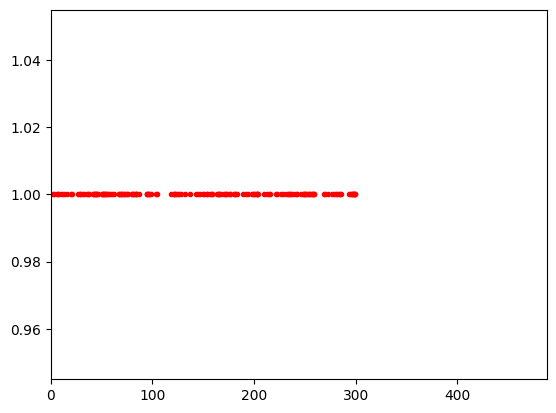

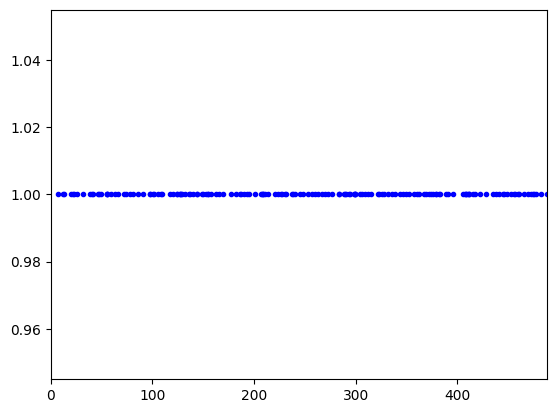

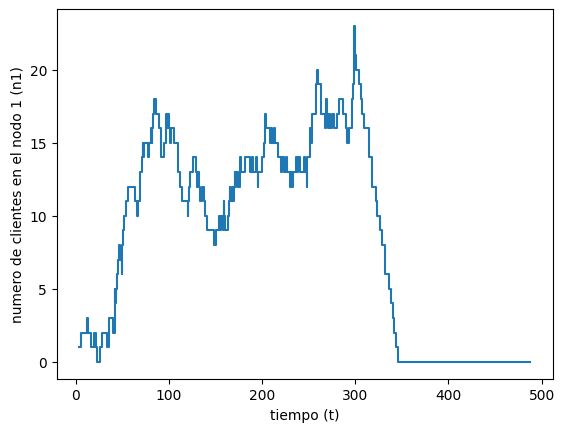

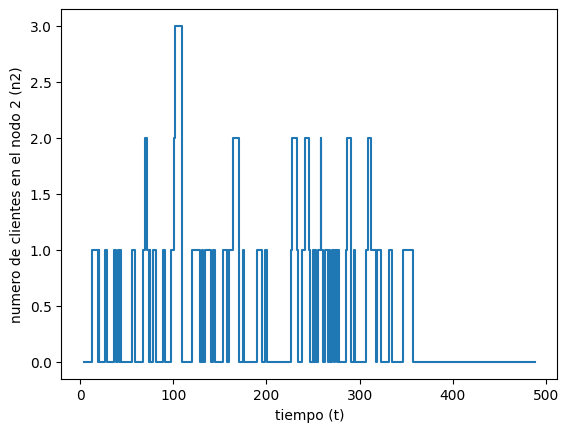

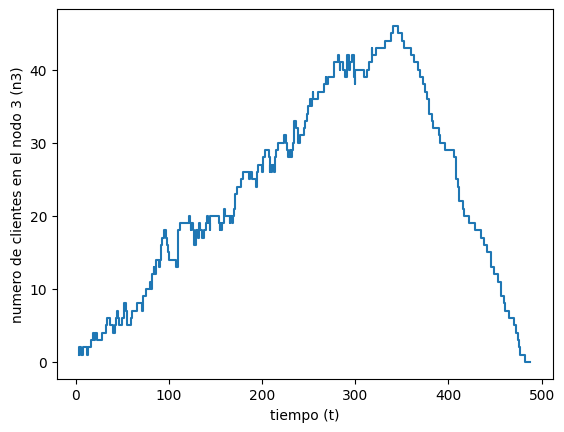

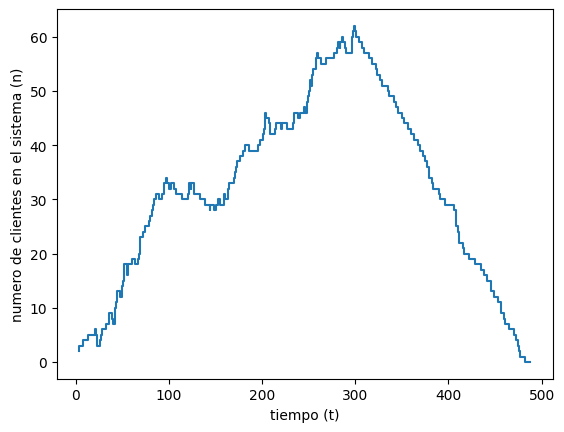

Tiempo medio de los clientes en el sistema (t_med_sistema):  98.04849860599822
Número promedio de clientes en el nodo 1 (n_med_n1):  8.529496862839236
Número promedio de clientes en el nodo 2 (n_med_n2):  0.39902979661039817
Número promedio de clientes en el nodo 3 (n_med_n3):  23.45017426019963
Tiempo transcurrido desde T hasta que el último cliente abandona el sistema:  187.85509665207513
Número máximo de clientes en el sistema:  62
Total de clientes que pasaron por el nodo 1 (n1):  161
Total de clientes que pasaron por el nodo 2 (n2):  68
Total de clientes que pasaron por el nodo 3 (n3):  161
Total de clientes que pasaron por el sistema:  161


In [4]:
at = np.array(at)
an1 = np.array(an1)
an2 = np.array(an2)
an3 = np.array(an3)
an = np.array(an)

LLt = np.array(LLt)
St = np.array(St)

tmp = np.zeros((len(LLt)))+1

plt.plot(LLt, tmp, 'r.')
plt.xlim(0, max(at))
plt.show()

tmp = np.zeros((len(St)))+1

plt.plot(St, tmp, 'b.')
plt.xlim(0, max(at))
plt.show()

plt.step(at,an1)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el nodo 1 (n1)')
plt.show()

plt.step(at,an2)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el nodo 2 (n2)')
plt.show()

plt.step(at,an3)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el nodo 3 (n3)')
plt.show()

plt.step(at,an)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el sistema (n)')
plt.show()

print("Tiempo medio de los clientes en el sistema (t_med_sistema): ",t_med_sistema)
print("Número promedio de clientes en el nodo 1 (n_med_n1): ",n_med_n1)
print("Número promedio de clientes en el nodo 2 (n_med_n2): ",n_med_n2)
print("Número promedio de clientes en el nodo 3 (n_med_n3): ",n_med_n3)
print("Tiempo transcurrido desde T hasta que el último cliente abandona el sistema: ",Tp)
print("Número máximo de clientes en el sistema: ",max(an))
print("Total de clientes que pasaron por el nodo 1 (n1): ",NS1)
print("Total de clientes que pasaron por el nodo 2 (n2): ",NS2)
print("Total de clientes que pasaron por el nodo 3 (n3): ",NS3)
print("Total de clientes que pasaron por el sistema: ",NLL3)

### 20 repeticiones

In [5]:
T = 300.0
L = 2.0
mu1 = 2.1
sigma1 = 0.5
mu2 = 2.4
mu31 = 4.1
sigma31 = 2.5
mu32 = 3.0
sigma32 = 2.0

resultados = []

for rep in range(20):
    np.random.seed(rep)

    M = 999999.0

    at = []
    LLt = []
    St = []
    an1 = []
    an2 = []
    an3 = []
    an = []

    t = tsuc = Tp = 0

    NLL1 = NLL2 = NLL3 = NS1 = NS2 = NS3 = n1 = n2 = n3 = 0

    n_med_n1 = n_med_n2 = n_med_n3 = 0


    TSuc = {"tLL1":M, "tS1":M, "tS2":M, "tS3":M}

    LL1 = []
    LL2 = []
    LL3 = []

    S1 = []
    S2 = []
    S3 = []

    X = np.random.exponential(L)

    if X > T:
        Tp = t_med_sistema = 0.0
        n_med_n1 = n_med_n2 = n_med_n3 = 0
    else:
        Llegada_cliente(X)
        while (min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']])!=M):
            if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tLL1']:
                tsuc = TSuc['tLL1']
                TSuc['tLL1'] = M
                Llegada_cliente(tsuc)
            if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS1']:
                tsuc = TSuc['tS1']
                TSuc['tS1'] = M
                Servicio_nodo1(tsuc)
            if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS2']:
                tsuc = TSuc['tS2']
                TSuc['tS2'] = M
                Servicio_nodo2(tsuc)
            if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS3']:
                tsuc = TSuc['tS3']
                TSuc['tS3'] = M
                Servicio_nodo3(tsuc)
            at.append(tsuc)
            an1.append(n1)
            an2.append(n2)
            an3.append(n3)
            an.append(n1+n2+n3)

        Tp = max(0,t-T)
        acumulo1 = acumulo2 = acumulo3 = 0.0

        ind = 0
        while ind < NLL1:
            acumulo1 = acumulo1 + S1[ind] - LL1[ind]
            ind = ind + 1
        ind = 0
        while ind < NLL2:
            acumulo2 = acumulo2 + S2[ind] - LL2[ind]
            ind = ind + 1
        ind = 0
        while ind < NLL3:
            acumulo3 = acumulo3 + S3[ind] - LL3[ind]
            ind = ind + 1

        t_med_sistema = (acumulo1/NLL1) + (0.4*acumulo2/NLL2) + (acumulo3/NLL3)

        n_med_n1 = n_med_n1 / t
        n_med_n2 = n_med_n2 / t
        n_med_n3 = n_med_n3 / t

    resultados.append([t_med_sistema, n_med_n1, n_med_n2, n_med_n3, Tp,
                       max(an) if len(an) > 0 else 0, NS1, NS2, NS3, NLL3])

columnas = ['t_med_sistema', 'n_med_n1', 'n_med_n2', 'n_med_n3', 'Tp', 'max_clientes',
            'total_nodo1', 'total_nodo2', 'total_nodo3', 'total_sistema']

red_A = pd.DataFrame(resultados, columns=columnas, index=range(1, 21))
red_A

,t_med_sistema,n_med_n1,n_med_n2,n_med_n3,Tp,max_clientes,total_nodo1,total_nodo2,total_nodo3,total_sistema
1,86.767013,6.445704,0.653684,23.051679,174.981229,66,165,67,165,165
2,108.248404,7.678988,0.401282,24.197807,223.425021,63,156,65,156,156
3,114.697680,9.409553,0.381090,26.623501,200.852741,65,159,64,159,159
4,89.991548,3.446067,0.466311,25.325307,152.095203,54,147,56,147,147
5,55.059803,1.890129,0.325760,13.849982,119.313151,34,123,39,123,123
6,107.620621,6.171263,0.413170,28.084474,199.650372,69,161,63,161,161
7,51.121843,3.614037,0.559016,12.482706,91.387929,29,128,46,128,128
8,97.517892,6.832964,0.536763,24.070216,192.200445,60,159,57,159,159
9,72.283488,1.731751,0.385514,19.385451,147.211324,41,133,54,133,133
10,81.301983,3.138060,0.292970,23.949585,132.518947,51,146,48,146,146


In [6]:
def resumen(df):
    n = len(df)
    tval = stats.t.ppf(0.975, n - 1)
    media = df.mean()
    desv = df.std(ddof=1)
    error = tval * desv / math.sqrt(n)
    return pd.DataFrame({'media': media, 'desv_estandar': desv,
                         'IC95%_inferior': media - error, 'IC95%_superior': media + error}).round(3)

resumen_A = resumen(red_A)
resumen_A

,media,desv_estandar,IC95%_inferior,IC95%_superior
t_med_sistema,86.259,18.222,77.731,94.787
n_med_n1,5.429,2.466,4.274,6.583
n_med_n2,0.432,0.110,0.381,0.484
n_med_n3,21.715,4.243,19.729,23.700
Tp,164.739,34.104,148.778,180.700
max_clientes,53.050,11.283,47.769,58.331
total_nodo1,148.450,12.280,142.703,154.197
total_nodo2,59.550,8.733,55.463,63.637
total_nodo3,148.450,12.280,142.703,154.197
total_sistema,148.450,12.280,142.703,154.197


## Escenario B

T = 300 · tiempos entre llegadas ~ Exponencial(λ = 3) · N1 ~ Normal(μ1 = 3.0, σ1 = 1.0) · N2 ~ Exponencial(μ2 = 1.5) · N3 ~ Normal(μ31 = 4.0, σ31 = 2.0) si n3 < 5, Normal(μ32 = 2.0, σ32 = 1.5) si n3 ≥ 5

### Ejecución única

In [7]:
T = 300.0
L = 3.0
mu1 = 3.0
sigma1 = 1.0
mu2 = 1.5
mu31 = 4.0
sigma31 = 2.0
mu32 = 2.0
sigma32 = 1.5

M = 999999.0

#np.random.seed(137)

at = []
LLt = []
St = []
an1 = []
an2 = []
an3 = []
an = []

t = tsuc = Tp = 0

NLL1 = NLL2 = NLL3 = NS1 = NS2 = NS3 = n1 = n2 = n3 = 0

n_med_n1 = n_med_n2 = n_med_n3 = 0


TSuc = {"tLL1":M, "tS1":M, "tS2":M, "tS3":M}

LL1 = []
LL2 = []
LL3 = []

S1 = []
S2 = []
S3 = []

X = np.random.exponential(L)

if X > T:
    Tp = t_med_sistema = 0.0
    n_med_n1 = n_med_n2 = n_med_n3 = 0
else:
    Llegada_cliente(X)
    while (min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']])!=M):
        if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tLL1']:
            tsuc = TSuc['tLL1']
            TSuc['tLL1'] = M
            Llegada_cliente(tsuc)
        if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS1']:
            tsuc = TSuc['tS1']
            TSuc['tS1'] = M
            Servicio_nodo1(tsuc)
        if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS2']:
            tsuc = TSuc['tS2']
            TSuc['tS2'] = M
            Servicio_nodo2(tsuc)
        if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS3']:
            tsuc = TSuc['tS3']
            TSuc['tS3'] = M
            Servicio_nodo3(tsuc)
        at.append(tsuc)
        an1.append(n1)
        an2.append(n2)
        an3.append(n3)
        an.append(n1+n2+n3)

    Tp = max(0,t-T)
    acumulo1 = acumulo2 = acumulo3 = 0.0

    ind = 0
    while ind < NLL1:
        acumulo1 = acumulo1 + S1[ind] - LL1[ind]
        ind = ind + 1
    ind = 0
    while ind < NLL2:
        acumulo2 = acumulo2 + S2[ind] - LL2[ind]
        ind = ind + 1
    ind = 0
    while ind < NLL3:
        acumulo3 = acumulo3 + S3[ind] - LL3[ind]
        ind = ind + 1

    t_med_sistema = (acumulo1/NLL1) + (0.4*acumulo2/NLL2) + (acumulo3/NLL3)

    n_med_n1 = n_med_n1 / t
    n_med_n2 = n_med_n2 / t
    n_med_n3 = n_med_n3 / t

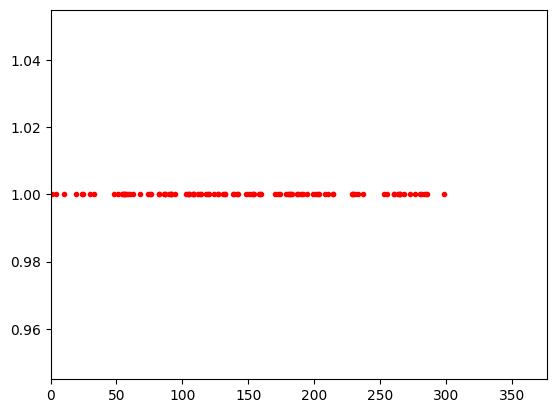

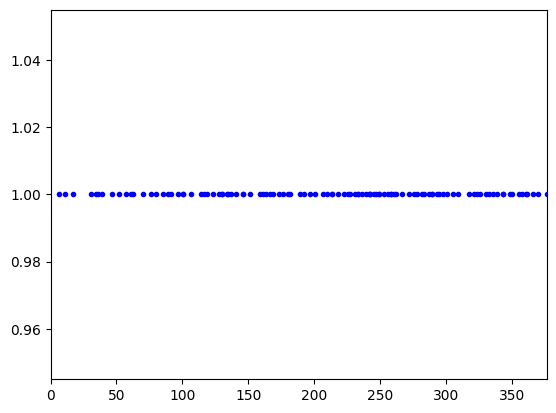

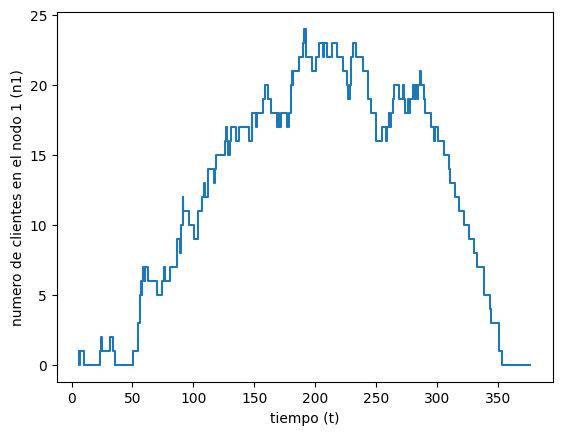

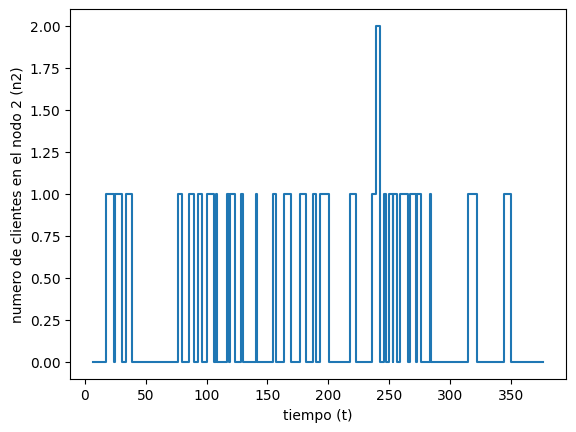

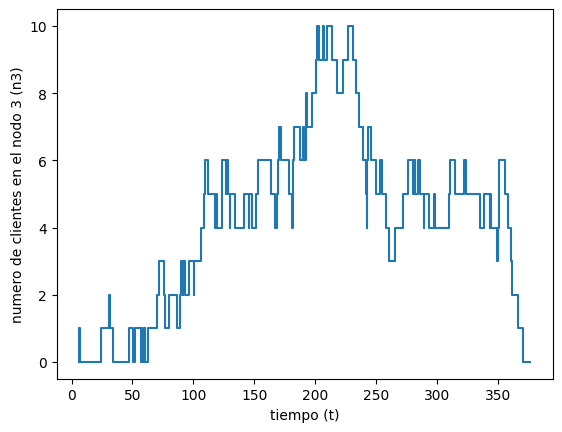

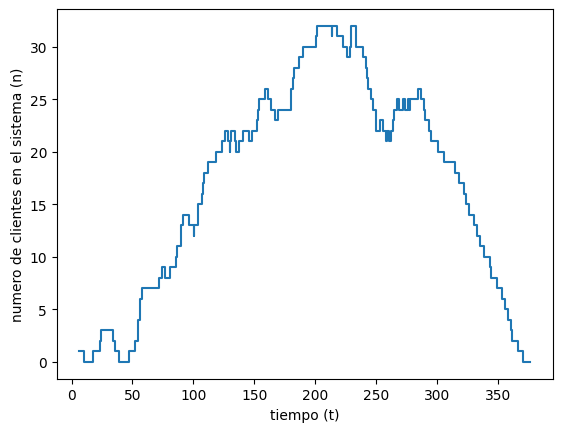

Tiempo medio de los clientes en el sistema (t_med_sistema):  58.680903398986125
Número promedio de clientes en el nodo 1 (n_med_n1):  12.237167157268733
Número promedio de clientes en el nodo 2 (n_med_n2):  0.2798369577704468
Número promedio de clientes en el nodo 3 (n_med_n3):  4.495405995045568
Tiempo transcurrido desde T hasta que el último cliente abandona el sistema:  76.4215962874975
Número máximo de clientes en el sistema:  32
Total de clientes que pasaron por el nodo 1 (n1):  109
Total de clientes que pasaron por el nodo 2 (n2):  47
Total de clientes que pasaron por el nodo 3 (n3):  109
Total de clientes que pasaron por el sistema:  109


In [8]:
at = np.array(at)
an1 = np.array(an1)
an2 = np.array(an2)
an3 = np.array(an3)
an = np.array(an)

LLt = np.array(LLt)
St = np.array(St)

tmp = np.zeros((len(LLt)))+1

plt.plot(LLt, tmp, 'r.')
plt.xlim(0, max(at))
plt.show()

tmp = np.zeros((len(St)))+1

plt.plot(St, tmp, 'b.')
plt.xlim(0, max(at))
plt.show()

plt.step(at,an1)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el nodo 1 (n1)')
plt.show()

plt.step(at,an2)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el nodo 2 (n2)')
plt.show()

plt.step(at,an3)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el nodo 3 (n3)')
plt.show()

plt.step(at,an)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el sistema (n)')
plt.show()

print("Tiempo medio de los clientes en el sistema (t_med_sistema): ",t_med_sistema)
print("Número promedio de clientes en el nodo 1 (n_med_n1): ",n_med_n1)
print("Número promedio de clientes en el nodo 2 (n_med_n2): ",n_med_n2)
print("Número promedio de clientes en el nodo 3 (n_med_n3): ",n_med_n3)
print("Tiempo transcurrido desde T hasta que el último cliente abandona el sistema: ",Tp)
print("Número máximo de clientes en el sistema: ",max(an))
print("Total de clientes que pasaron por el nodo 1 (n1): ",NS1)
print("Total de clientes que pasaron por el nodo 2 (n2): ",NS2)
print("Total de clientes que pasaron por el nodo 3 (n3): ",NS3)
print("Total de clientes que pasaron por el sistema: ",NLL3)

### 20 repeticiones

In [9]:
T = 300.0
L = 3.0
mu1 = 3.0
sigma1 = 1.0
mu2 = 1.5
mu31 = 4.0
sigma31 = 2.0
mu32 = 2.0
sigma32 = 1.5

resultados = []

for rep in range(20):
    np.random.seed(rep)

    M = 999999.0

    at = []
    LLt = []
    St = []
    an1 = []
    an2 = []
    an3 = []
    an = []

    t = tsuc = Tp = 0

    NLL1 = NLL2 = NLL3 = NS1 = NS2 = NS3 = n1 = n2 = n3 = 0

    n_med_n1 = n_med_n2 = n_med_n3 = 0


    TSuc = {"tLL1":M, "tS1":M, "tS2":M, "tS3":M}

    LL1 = []
    LL2 = []
    LL3 = []

    S1 = []
    S2 = []
    S3 = []

    X = np.random.exponential(L)

    if X > T:
        Tp = t_med_sistema = 0.0
        n_med_n1 = n_med_n2 = n_med_n3 = 0
    else:
        Llegada_cliente(X)
        while (min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']])!=M):
            if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tLL1']:
                tsuc = TSuc['tLL1']
                TSuc['tLL1'] = M
                Llegada_cliente(tsuc)
            if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS1']:
                tsuc = TSuc['tS1']
                TSuc['tS1'] = M
                Servicio_nodo1(tsuc)
            if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS2']:
                tsuc = TSuc['tS2']
                TSuc['tS2'] = M
                Servicio_nodo2(tsuc)
            if min([TSuc['tLL1'],TSuc['tS1'],TSuc['tS2'],TSuc['tS3']]) == TSuc['tS3']:
                tsuc = TSuc['tS3']
                TSuc['tS3'] = M
                Servicio_nodo3(tsuc)
            at.append(tsuc)
            an1.append(n1)
            an2.append(n2)
            an3.append(n3)
            an.append(n1+n2+n3)

        Tp = max(0,t-T)
        acumulo1 = acumulo2 = acumulo3 = 0.0

        ind = 0
        while ind < NLL1:
            acumulo1 = acumulo1 + S1[ind] - LL1[ind]
            ind = ind + 1
        ind = 0
        while ind < NLL2:
            acumulo2 = acumulo2 + S2[ind] - LL2[ind]
            ind = ind + 1
        ind = 0
        while ind < NLL3:
            acumulo3 = acumulo3 + S3[ind] - LL3[ind]
            ind = ind + 1

        t_med_sistema = (acumulo1/NLL1) + (0.4*acumulo2/NLL2) + (acumulo3/NLL3)

        n_med_n1 = n_med_n1 / t
        n_med_n2 = n_med_n2 / t
        n_med_n3 = n_med_n3 / t

    resultados.append([t_med_sistema, n_med_n1, n_med_n2, n_med_n3, Tp,
                       max(an) if len(an) > 0 else 0, NS1, NS2, NS3, NLL3])

columnas = ['t_med_sistema', 'n_med_n1', 'n_med_n2', 'n_med_n3', 'Tp', 'max_clientes',
            'total_nodo1', 'total_nodo2', 'total_nodo3', 'total_sistema']

red_B = pd.DataFrame(resultados, columns=columnas, index=range(1, 21))
red_B

,t_med_sistema,n_med_n1,n_med_n2,n_med_n3,Tp,max_clientes,total_nodo1,total_nodo2,total_nodo3,total_sistema
1,31.964605,5.346629,0.253004,4.183624,25.073096,19,99,49,99,99
2,19.263461,1.678949,0.130765,3.106054,31.569537,9,85,29,85,85
3,43.895526,9.326203,0.169346,4.678257,33.536648,23,108,35,108,108
4,36.066257,6.521874,0.156293,4.293563,34.341745,18,102,34,102,102
5,30.915249,4.561138,0.161973,4.128897,55.153627,18,102,35,102,102
6,24.125551,2.414966,0.161972,4.014844,19.259963,12,87,39,87,87
7,21.522129,1.858669,0.128377,3.741857,15.439509,10,84,33,84,84
8,24.973342,3.256758,0.218823,3.858915,17.093854,13,93,39,93,93
9,36.571100,6.207049,0.216940,4.091844,45.148507,21,99,45,99,99
10,35.458410,5.916616,0.150510,3.679300,59.062280,18,99,33,99,99


In [10]:
resumen_B = resumen(red_B)
resumen_B

,media,desv_estandar,IC95%_inferior,IC95%_superior
t_med_sistema,33.053,9.545,28.586,37.520
n_med_n1,5.501,2.934,4.128,6.875
n_med_n2,0.191,0.045,0.170,0.212
n_med_n3,4.188,0.493,3.957,4.419
Tp,39.436,19.187,30.456,48.415
max_clientes,17.650,5.687,14.988,20.312
total_nodo1,100.400,9.752,95.836,104.964
total_nodo2,40.950,8.069,37.174,44.726
total_nodo3,100.400,9.752,95.836,104.964
total_sistema,100.400,9.752,95.836,104.964
